# Praktikum Stereo Vision — Kalibrasi Kamera, Disparity, dan Estimasi Jarak
Jalankan sel dari atas ke bawah. Foto diambil otomatis dari GitHub (`Praktikum_Stereo/Calibration/gmb_*.jpg` dan foto stereo).

In [ ]:
from pathlib import Path
import re
import csv
import math
import subprocess
import shutil

import cv2
import numpy as np
import matplotlib.pyplot as plt

PATTERN_SIZE = (9, 6)       # Sudut dalam chessboard (kolom, baris)
SQUARE_SIZE_MM = 25.0       # Ukuran satu kotak chessboard (mm)
BASELINE_CM = 20.0          # Perpindahan kamera kiri ke kanan (cm)

REPO_URL = 'https://github.com/Felixriq/Praktikum_Stereo_Vision.git'
REPO_DIR = Path('repo_stereo')

DATA_NAME = 'Praktikum_Stereo'
CAL_NAME = 'Calibration'
STEREO_NAME = 'Stereo'

# True = selalu clone ulang repository terbaru
CLONE_FROM_GITHUB = True

# Pilihan pasangan foto:
# 0 = 0.5 meter
# 1 = 1.0 meter
# 2 = 1.5 meter
PAIR_INDEX = 2

# None = deteksi otomatis seluruh pasangan foto
STEREO_LEFT_REL = None
STEREO_RIGHT_REL = None

if CLONE_FROM_GITHUB:
    # Hapus repository lama agar tidak membaca dataset sebelumnya
    if REPO_DIR.exists():
        print("Menghapus repository clone lama...")
        shutil.rmtree(REPO_DIR)
    print("Mengunduh repository terbaru dari GitHub...")
    result = subprocess.run(
        [
            'git',
            'clone',
            '--depth',
            '1',
            REPO_URL,
            str(REPO_DIR)],
        capture_output=True,
        text=True)

    if result.returncode != 0:
        raise RuntimeError(
            "Git clone gagal!\n" + result.stderr)

    print("Repository berhasil diunduh!")
else:
    if not REPO_DIR.exists():
        raise FileNotFoundError(
            "Repository tidak ditemukan. "
            "Aktifkan CLONE_FROM_GITHUB=True.")

def find_child(parent, name):
    for p in parent.iterdir():

        if p.is_dir() and p.name.lower() == name.lower():
            return p
    return None

DATA_DIR = find_child(REPO_DIR, DATA_NAME)

if DATA_DIR is None:
    raise FileNotFoundError(
        f"Folder {DATA_NAME} tidak ditemukan.\n"
        f"Isi repository: {[p.name for p in REPO_DIR.iterdir()]}")

CAL_DIR = find_child(DATA_DIR, CAL_NAME)
if CAL_DIR is None:
    raise FileNotFoundError(
        f"Folder {CAL_NAME} tidak ditemukan di {DATA_DIR}")

STEREO_DIR = find_child(DATA_DIR, STEREO_NAME)
if STEREO_DIR is None:
    raise FileNotFoundError(
        f"Folder {STEREO_NAME} tidak ditemukan di {DATA_DIR}")

# Folder output
OUT = DATA_DIR / 'output'
OUT.mkdir(parents=True, exist_ok=True)

IMAGE_EXT = {'.jpg', '.jpeg', '.png', '.bmp'}

def nkey(p):
    """
    Natural sorting:
    gmb_2.jpg akan muncul sebelum gmb_10.jpg
    """

    return [
        int(t) if t.isdigit() else t.lower()
        for t in re.split(r'(\d+)', p.name)]


cal_files = sorted(
    [
        p for p in CAL_DIR.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXT
    ],
    key=nkey)

def is_left(stem):
    return re.search(
        r'(^|[_\-\s])(left|kiri)(?=$|[_\-\s\d])',
        stem.lower()) is not None


def is_right(stem):
    return re.search(
        r'(^|[_\-\s])(right|kanan)(?=$|[_\-\s\d])',
        stem.lower()) is not None

pairs = []

if STEREO_LEFT_REL and STEREO_RIGHT_REL:
    left_path = DATA_DIR / STEREO_LEFT_REL
    right_path = DATA_DIR / STEREO_RIGHT_REL
    if not left_path.exists():
        raise FileNotFoundError(f"Foto kiri tidak ditemukan: {left_path}")
    if not right_path.exists():
        raise FileNotFoundError(f"Foto kanan tidak ditemukan: {right_path}")
    pairs = [(left_path, right_path)]

else:
    stereo_files = [
        p for p in STEREO_DIR.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXT]

    left_files = sorted(
        [p for p in stereo_files if is_left(p.stem)],
        key=nkey)

    right_files = sorted(
        [p for p in stereo_files if is_right(p.stem)],
        key=nkey)

    if len(left_files) != len(right_files):

        raise RuntimeError(
            "Jumlah foto kiri dan kanan tidak sama!\n"
            f"Foto kiri: {[p.name for p in left_files]}\n"
            f"Foto kanan: {[p.name for p in right_files]}")

    # Memasangkan foto berdasarkan urutan nama
    pairs = list(zip(left_files, right_files))

    if not pairs:
        raise FileNotFoundError(
            "Tidak ditemukan pasangan foto stereo "
            "di folder Stereo.")

def distance_key(pair):
    name = pair[0].stem.lower()
    match = re.search(
        r'(\d+(?:[,.]\d+)?)\s*m',
        name)

    if match:
        distance = float(
            match.group(1).replace(',', '.'))
        return (0, distance)

    # Foto tanpa informasi jarak diletakkan di belakang
    return (1, float('inf'))

pairs = sorted(pairs, key=distance_key)

print("\n" + "=" * 55)
print("DAFTAR PASANGAN FOTO STEREO")
print("=" * 55)

for i, (left_file, right_file) in enumerate(pairs):
    print(
        f"Pasangan {i}: "
        f"kiri={left_file.name} | "
        f"kanan={right_file.name}")

if PAIR_INDEX < 0 or PAIR_INDEX >= len(pairs):
    raise IndexError(
        f"PAIR_INDEX={PAIR_INDEX} tidak valid. "
        f"Jumlah pasangan tersedia: {len(pairs)}")

L_PATH, R_PATH = pairs[PAIR_INDEX]

print("\n" + "=" * 55)
print("INFORMASI DATASET")
print("=" * 55)

print("Repository :", REPO_URL)
print("Folder data:", DATA_DIR.resolve())
print("Kalibrasi  :", CAL_DIR.resolve())
print("Stereo     :", STEREO_DIR.resolve())

print("\nFoto kalibrasi:", len(cal_files))
print("Jumlah pasangan stereo:", len(pairs))

print("\nPasangan yang dipilih:")
print("Foto kiri :", L_PATH.name)
print("Foto kanan:", R_PATH.name)

print("\nOpenCV:", cv2.__version__)

print("Ukuran kotak:", SQUARE_SIZE_MM, "mm")
print("Baseline:", BASELINE_CM, "cm")

if not cal_files:
    raise RuntimeError("Foto kalibrasi tidak ditemukan!")

if not L_PATH.exists() or not R_PATH.exists():
    raise FileNotFoundError(
        f"Foto stereo tidak ditemukan:\n{L_PATH}\n{R_PATH}")

left_test = cv2.imread(str(L_PATH))
right_test = cv2.imread(str(R_PATH))

if left_test is None:
    raise RuntimeError(
        f"OpenCV gagal membaca foto kiri: {L_PATH}")

if right_test is None:
    raise RuntimeError(
        f"OpenCV gagal membaca foto kanan: {R_PATH}")

print("\nResolusi foto kiri :", left_test.shape)
print("Resolusi foto kanan:", right_test.shape)

if left_test.shape != right_test.shape:
    print(
        "\nPERINGATAN: Resolusi foto kiri dan kanan berbeda!")

else:
    print("\nResolusi kedua foto sama!")

if SQUARE_SIZE_MM <= 0 or BASELINE_CM <= 0:
    raise ValueError(
        "Ukuran kotak dan baseline harus lebih besar dari nol.")

if len(cal_files) < 10:
    raise RuntimeError(
        "Sediakan minimal 10 foto kalibrasi "
        "(disarankan 15–25 foto)."
)

print("\n" + "=" * 55)
print("CELL A BERHASIL DIJALANKAN")
print("=" * 55)

Menghapus repository clone lama...
Mengunduh repository terbaru dari GitHub...
Repository berhasil diunduh!

DAFTAR PASANGAN FOTO STEREO
Pasangan 0: kiri=left_0,5m.jpeg | kanan=right_0,5m.jpeg
Pasangan 1: kiri=left_1m.jpeg | kanan=right_1m.jpeg
Pasangan 2: kiri=left_1,5m.jpeg | kanan=right_1,5m.jpeg

INFORMASI DATASET
Repository : https://github.com/Felixriq/Praktikum_Stereo_Vision.git
Folder data: /content/repo_stereo/Praktikum_Stereo
Kalibrasi  : /content/repo_stereo/Praktikum_Stereo/Calibration
Stereo     : /content/repo_stereo/Praktikum_Stereo/stereo

Foto kalibrasi: 20
Jumlah pasangan stereo: 3

Pasangan yang dipilih:
Foto kiri : left_1,5m.jpeg
Foto kanan: right_1,5m.jpeg

OpenCV: 5.0.0
Ukuran kotak: 25.0 mm
Baseline: 20.0 cm

Resolusi foto kiri : (1792, 2389, 3)
Resolusi foto kanan: (1792, 2389, 3)

Resolusi kedua foto sama!

CELL A BERHASIL DIJALANKAN


Resolusi foto kalibrasi: {(2390, 1792): 20}
Foto valid: 20 | Gagal: 0
Foto gagal: []
Contoh jarak dua sudut dalam piksel: 156.4


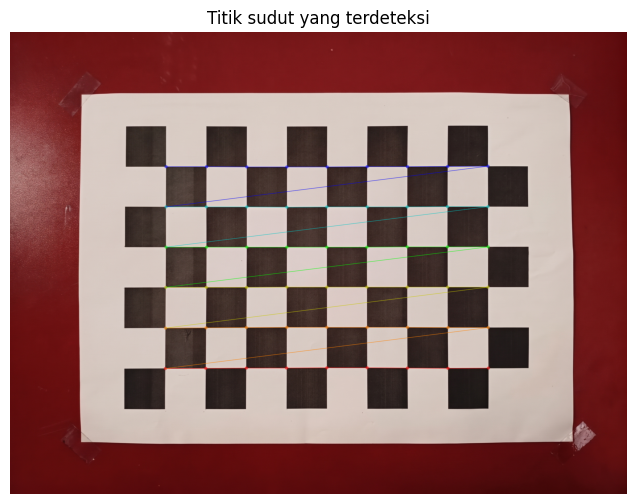

In [ ]:
CRIT = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.01)

def detect_corners(gray, pattern, det_max=2000):
    """Deteksi di gambar yang diperkecil (cepat), lalu haluskan di resolusi penuh."""
    s = min(1.0, det_max / max(gray.shape))
    small = cv2.resize(gray, None, fx=s, fy=s, interpolation=cv2.INTER_AREA) if s < 1 else gray
    found, c = cv2.findChessboardCornersSB(small, pattern, flags=cv2.CALIB_CB_NORMALIZE_IMAGE)
    if not found:
        found, c = cv2.findChessboardCorners(
            small, pattern, cv2.CALIB_CB_ADAPTIVE_THRESH + cv2.CALIB_CB_NORMALIZE_IMAGE)
    if not found:
        return False, None
    c = (c.astype(np.float32) / s).reshape(-1, 1, 2)
    c = cv2.cornerSubPix(gray, c, (11, 11), (-1, -1), CRIT)
    return True, c

def read_gray(path):
    img = cv2.imread(str(path))
    return img, (None if img is None else cv2.cvtColor(img, cv2.COLOR_BGR2GRAY))

# Bila pola yang diisi tidak terdeteksi pada foto awal, coba ukuran pola umum lain
probe = [read_gray(p)[1] for p in cal_files[:3]]
probe = [g for g in probe if g is not None]
n_hit = sum(detect_corners(g, PATTERN_SIZE)[0] for g in probe)
if n_hit < max(1, len(probe) - 1):
    print(f'PATTERN_SIZE={PATTERN_SIZE} gagal pada foto awal ({n_hit}/{len(probe)}). Mencoba ukuran lain...')
    cands = sorted({(a, b) for a in range(5, 13) for b in range(4, 10) if a > b},
                   key=lambda t: -(t[0] * t[1]))
    for cand in cands:
        if sum(detect_corners(g, cand)[0] for g in probe) >= max(1, len(probe) - 1):
            print(f'Ukuran pola yang cocok: {cand} -> dipakai. Samakan README/PATTERN_SIZE.')
            PATTERN_SIZE = cand
            break
    else:
        print('Tidak ada ukuran pola yang cocok. Periksa foto: papan harus terlihat utuh dan tidak buram.')

cols, rows = PATTERN_SIZE
obj = np.zeros((cols * rows, 3), np.float32)
obj[:, :2] = np.mgrid[0:cols, 0:rows].T.reshape(-1, 2) * SQUARE_SIZE_MM
objpoints, imgpoints, ok_files, bad_files, spacings = [], [], [], [], []
from collections import Counter
sizes = {}
for path in cal_files:
    im = cv2.imread(str(path))
    if im is not None: sizes[path.name] = (im.shape[1], im.shape[0])
size_count = Counter(sizes.values())
print('Resolusi foto kalibrasi:', dict(size_count))
size_wh = size_count.most_common(1)[0][0]      # resolusi terbanyak dipakai sebagai acuan
preview = None
for path in cal_files:
    img, gray = read_gray(path)
    if img is None:
        bad_files.append(path.name); continue
    wh = (gray.shape[1], gray.shape[0])
    if wh != size_wh:
        bad_files.append(path.name + ' (resolusi berbeda)'); continue
    found, corners = detect_corners(gray, PATTERN_SIZE)
    if not found:
        bad_files.append(path.name); continue
    objpoints.append(obj.copy()); imgpoints.append(corners)
    ok_files.append(path.name)
    spacings.append(float(np.linalg.norm(corners[1, 0] - corners[0, 0])))
    if preview is None:
        preview = img.copy()
        cv2.drawChessboardCorners(preview, PATTERN_SIZE, corners, True)
print('Foto valid:', len(ok_files), '| Gagal:', len(bad_files))
print('Foto gagal:', bad_files)
print('Contoh jarak dua sudut dalam piksel:', round(spacings[0], 2) if spacings else None)
if preview is not None:
    plt.figure(figsize=(10, 6)); plt.imshow(cv2.cvtColor(preview, cv2.COLOR_BGR2RGB))
    plt.title('Titik sudut yang terdeteksi'); plt.axis('off'); plt.show()
    cv2.imwrite(str(OUT / 'corners_preview.jpg'), preview)
if len(ok_files) < 10: raise RuntimeError('Titik sudut berhasil dideteksi pada <10 foto. Ulangi/ambil foto baru.')

In [ ]:
rms, K, dist, rvecs, tvecs = cv2.calibrateCamera(objpoints, imgpoints, size_wh, None, None)
fx, fy, cx, cy = K[0, 0], K[1, 1], K[0, 2], K[1, 2]
print('Resolusi kalibrasi:', size_wh)
print('K =\n', K)
print(f'fx={fx:.2f} px | fy={fy:.2f} px | cx={cx:.2f} px | cy={cy:.2f} px')
print(f'RMS reprojection error={rms:.3f} px')
print('Distorsi:', dist.ravel())
np.savez(OUT / 'calibration.npz', K=K, dist=dist, image_wh=size_wh, rms=rms, square_size_mm=SQUARE_SIZE_MM)
if not np.isfinite(rms) or rms > 2.0:
    print('PERHATIAN: RMS cukup besar. Periksa foto kalibrasi dan kesesuaian pola.')

Resolusi kalibrasi: (2390, 1792)
K =
 [[1.85120106e+03 0.00000000e+00 1.19603106e+03]
 [0.00000000e+00 1.85631983e+03 8.91810981e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]
fx=1851.20 px | fy=1856.32 px | cx=1196.03 px | cy=891.81 px
RMS reprojection error=0.731 px
Distorsi: [ 1.14080226e-01 -4.63248692e-01  1.92388969e-04  1.96626157e-04
  4.25377139e-01]


In [ ]:
errs = []
for i in range(len(objpoints)):
    proj, _ = cv2.projectPoints(objpoints[i], rvecs[i], tvecs[i], K, dist)
    d = imgpoints[i].reshape(-1, 2) - proj.reshape(-1, 2)
    errs.append(float(np.sqrt(np.mean(np.sum(d ** 2, axis=1)))))
for n, e in sorted(zip(ok_files, errs), key=lambda t: -t[1]):
    print(n, round(e, 3))
print('Rata-rata:', round(float(np.mean(errs)), 3))

gmb_10.jpg 1.286
gmb_16.jpg 1.043
gmb_11.jpg 1.006
gmb_13.jpg 0.995
gmb_8.jpg 0.98
gmb_6.jpg 0.782
gmb_14.jpg 0.767
gmb_12.jpg 0.692
gmb_19.jpg 0.588
gmb_9.jpg 0.585
gmb_1.jpg 0.568
gmb_5.jpg 0.553
gmb_20.jpg 0.553
gmb_2.jpg 0.537
gmb_18.jpg 0.519
gmb_3.jpg 0.515
gmb_7.jpg 0.494
gmb_17.jpg 0.478
gmb_4.jpg 0.47
gmb_15.jpg 0.389
Rata-rata: 0.69


In [ ]:
def calib(exclude=(), fix_k3=False):
    idx = [i for i, n in enumerate(ok_files) if n not in exclude]
    flags = cv2.CALIB_FIX_K3 if fix_k3 else 0
    r, K2, d2, _, _ = cv2.calibrateCamera(
        [objpoints[i] for i in idx], [imgpoints[i] for i in idx],
        size_wh, None, None, flags=flags)
    return r, K2, d2.ravel(), len(idx)

# Foto dengan error terbesar dikeluarkan bertahap (otomatis, tidak lagi memakai nama file tetap)
worst = [n for n, _ in sorted(zip(ok_files, errs), key=lambda t: -t[1])]
skenario = [(), tuple(worst[:1]), tuple(worst[:2]), tuple(worst[:4])]
skenario = [ex for ex in skenario if len(ok_files) - len(ex) >= 8]
for ex in skenario:
    for fk in (False, True):
        r, K2, d2, n = calib(ex, fk)
        print(f'foto={n} fix_k3={fk} | RMS={r:.3f} | fx={K2[0,0]:.1f} fy={K2[1,1]:.1f} | '
              f'k1={d2[0]:.3f} k2={d2[1]:.3f} k3={d2[4]:.3f} | dikeluarkan={list(ex)}')

foto=20 fix_k3=False | RMS=0.731 | fx=1851.2 fy=1856.3 | k1=0.114 k2=-0.463 k3=0.425 | dikeluarkan=[]
foto=20 fix_k3=True | RMS=0.749 | fx=1854.7 fy=1859.8 | k1=0.080 k2=-0.230 k3=0.000 | dikeluarkan=[]
foto=19 fix_k3=False | RMS=0.685 | fx=1853.1 fy=1858.1 | k1=0.105 k2=-0.433 k3=0.388 | dikeluarkan=['gmb_10.jpg']
foto=19 fix_k3=True | RMS=0.702 | fx=1856.4 fy=1861.4 | k1=0.073 k2=-0.218 k3=0.000 | dikeluarkan=['gmb_10.jpg']
foto=18 fix_k3=False | RMS=0.660 | fx=1851.9 fy=1856.4 | k1=0.104 k2=-0.404 k3=0.334 | dikeluarkan=['gmb_10.jpg', 'gmb_16.jpg']
foto=18 fix_k3=True | RMS=0.673 | fx=1854.7 fy=1859.1 | k1=0.078 k2=-0.219 k3=0.000 | dikeluarkan=['gmb_10.jpg', 'gmb_16.jpg']
foto=16 fix_k3=False | RMS=0.598 | fx=1843.6 fy=1848.6 | k1=0.123 k2=-0.456 k3=0.399 | dikeluarkan=['gmb_10.jpg', 'gmb_16.jpg', 'gmb_11.jpg', 'gmb_13.jpg']
foto=16 fix_k3=True | RMS=0.619 | fx=1844.3 fy=1849.1 | k1=0.089 k2=-0.231 k3=0.000 | dikeluarkan=['gmb_10.jpg', 'gmb_16.jpg', 'gmb_11.jpg', 'gmb_13.jpg']


PERHATIAN foto kiri: (2389, 1792) -> (2390, 1792) (crop).
PERHATIAN foto kanan: (2389, 1792) -> (2390, 1792) (crop).
Matching: 1178 | Inlier: 940
Median beda baris = 1.20 px | Fraksi disparity positif = 100.0%


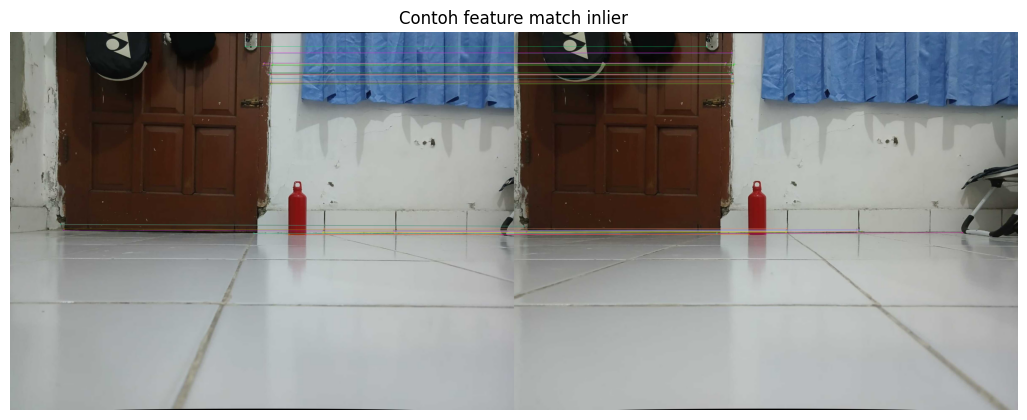

Alignment awal lolos pemeriksaan.
Jumlah titik pose valid: 832

HASIL STEREO RECTIFICATION
Median dy sebelum: 1.2 px
Median dy sesudah: 0.749 px
Focal length rectified: 1976.919 px
Baseline: 20.0 cm
Rectification: LULUS pemeriksaan vertikal.


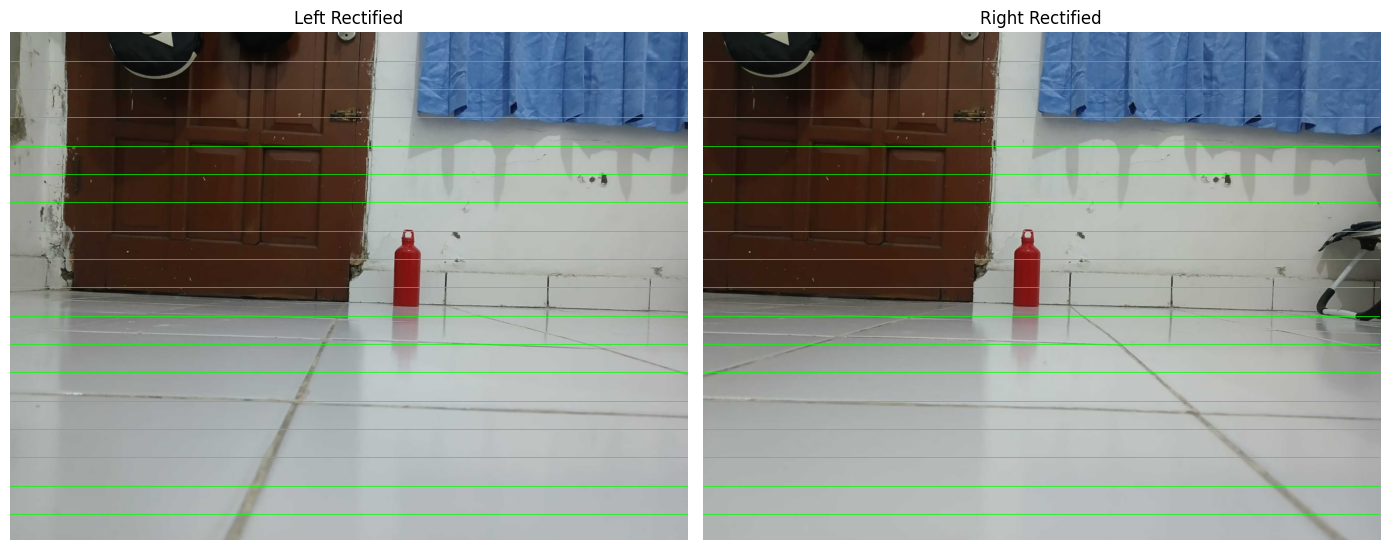

True

In [ ]:
STRICT_ALIGNMENT = False   # False = hanya peringatan bila alignment kurang baik (hasil depth jadi kurang andal)

left = cv2.imread(str(L_PATH)); right = cv2.imread(str(R_PATH))
if left is None or right is None: raise ValueError('Gagal membaca foto stereo')
# Samakan ukuran foto stereo dengan foto kalibrasi bila selisihnya kecil (mis. 2400 vs 2390 px).
# Intrinsik K hanya valid untuk ukuran/crop yang sama dengan foto kalibrasi.
FIX_MODE = 'crop'          # 'crop' = potong kelebihan piksel (disarankan) | 'resize' = ubah skala
CROP_ANCHOR_X = 'left'     # sisi yang DIPERTAHANKAN saat memotong lebar: 'left' | 'center' | 'right'
CROP_ANCHOR_Y = 'top'      # sisi yang DIPERTAHANKAN saat memotong tinggi: 'top' | 'center' | 'bottom'
MAX_FIX_FRAC = 0.02        # selisih lebih dari 2% dianggap salah foto/orientasi -> error

def fit_to(img, wh, name):
    h, w = img.shape[:2]
    tw, th = wh
    if (w, h) == (tw, th): return img
    if abs(w - tw) / tw > MAX_FIX_FRAC or abs(h - th) / th > MAX_FIX_FRAC:
        raise ValueError(f'{name}: resolusi {(w, h)} terlalu berbeda dari foto kalibrasi {wh}. '
                         'Cek orientasi portrait/landscape atau gunakan kamera/resolusi yang sama.')
    print(f'PERHATIAN {name}: {(w, h)} -> {wh} ({FIX_MODE}).')
    if FIX_MODE == 'resize':
        return cv2.resize(img, wh, interpolation=cv2.INTER_AREA)
    if w < tw or h < th:     # foto lebih kecil dari acuan: tambahkan tepi tiruan agar ukuran sama
        img = cv2.copyMakeBorder(img, 0, max(0, th - h), 0, max(0, tw - w), cv2.BORDER_REPLICATE)
        h, w = img.shape[:2]
    ox = {'left': 0, 'center': (w - tw) // 2, 'right': w - tw}[CROP_ANCHOR_X]
    oy = {'top': 0, 'center': (h - th) // 2, 'bottom': h - th}[CROP_ANCHOR_Y]
    return img[oy:oy + th, ox:ox + tw]

left = fit_to(left, size_wh, 'foto kiri')
right = fit_to(right, size_wh, 'foto kanan')
# Undistort mempertahankan koordinat intrinsik K (P=K)
map1, map2 = cv2.initUndistortRectifyMap(K, dist, None, K, size_wh, cv2.CV_32FC1)
left_u = cv2.remap(left, map1, map2, cv2.INTER_LINEAR)
right_u = cv2.remap(right, map1, map2, cv2.INTER_LINEAR)
lg = cv2.cvtColor(left_u, cv2.COLOR_BGR2GRAY)
rg = cv2.cvtColor(right_u, cv2.COLOR_BGR2GRAY)
orb = cv2.ORB_create(nfeatures=4500)
k1, des1 = orb.detectAndCompute(lg, None)
k2, des2 = orb.detectAndCompute(rg, None)
if des1 is None or des2 is None or len(k1) < 2 or len(k2) < 2:
    raise RuntimeError('Fitur foto kurang. Gunakan objek/latar bertekstur.')
matches = cv2.BFMatcher(cv2.NORM_HAMMING).knnMatch(des1, des2, k=2)
good = [m[0] for m in matches if len(m) == 2 and m[0].distance < 0.75 * m[1].distance]
if len(good) < 20: raise RuntimeError('Terlalu sedikit feature match. Ulangi foto dengan lebih banyak tekstur.')
pL = np.float32([k1[m.queryIdx].pt for m in good]); pR = np.float32([k2[m.trainIdx].pt for m in good])
# Fundamental matrix hanya untuk filter outlier, bukan mengganti rectification
F, mask = cv2.findFundamentalMat(pL, pR, cv2.FM_RANSAC, 1.5, 0.99)
if F is None or mask is None: raise RuntimeError('RANSAC gagal: pasangan foto sulit dicocokkan.')
inlier = mask.ravel().astype(bool)
if inlier.sum() < 15: raise RuntimeError('Inlier kurang dari 15. Ulangi foto.')
dy = np.abs(pL[inlier, 1] - pR[inlier, 1])
dx = pL[inlier, 0] - pR[inlier, 0]
median_dy = float(np.median(dy)); positive_fraction = float(np.mean(dx > 0))
print('Matching:', len(good), '| Inlier:', int(inlier.sum()))
print(f'Median beda baris = {median_dy:.2f} px | Fraksi disparity positif = {positive_fraction:.1%}')
vis = cv2.drawMatches(left_u, k1, right_u, k2, [m for m, v in zip(good, inlier) if v][:40], None,
                      flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
plt.figure(figsize=(13, 5)); plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
plt.title('Contoh feature match inlier'); plt.axis('off'); plt.show()
cv2.imwrite(str(OUT / 'matches.jpg'), vis)
ALIGNMENT_OK = (median_dy <= 2.0 and positive_fraction >= 0.70)

if ALIGNMENT_OK:
    print('Alignment awal lolos pemeriksaan.')

else:
    print('PERINGATAN: alignment awal kurang baik.')
    print('Mencoba memperbaiki alignment dengan stereo rectification.')

# Estimasi Essential Matrix dari pasangan fitur
E, mask_E = cv2.findEssentialMat(
    pL[inlier],
    pR[inlier],
    K,
    method=cv2.RANSAC,
    prob=0.999,
    threshold=1.0)

if E is None:
    raise RuntimeError('Essential Matrix gagal dihitung.')

# Estimasi rotasi dan arah translasi relatif kamera
pose_count, R_stereo, T_direction, pose_mask = cv2.recoverPose(
    E,
    pL[inlier],
    pR[inlier],
    K,
    mask=mask_E)

print('Jumlah titik pose valid:', pose_count)

if pose_count < 15:
    raise RuntimeError(
        'Estimasi pose kamera tidak cukup baik. '
        'Periksa kembali pasangan foto stereo.')

# Skala translasi menggunakan baseline fisik
T_norm = np.linalg.norm(T_direction)

if T_norm < 1e-9:
    raise RuntimeError('Arah translasi kamera tidak valid.')

T_stereo = (
    T_direction / T_norm
) * (BASELINE_CM / 100.0)

# Stereo rectification
# Gambar sebelumnya sudah melalui proses undistortion.
dist_zero = np.zeros((5, 1), dtype=np.float64)

R1, R2, P1, P2, Q, roi1, roi2 = cv2.stereoRectify(
    K, dist_zero,
    K, dist_zero,
    size_wh,
    R_stereo, T_stereo,
    flags=cv2.CALIB_ZERO_DISPARITY,
    alpha=0)

# Buat peta transformasi
mapL1, mapL2 = cv2.initUndistortRectifyMap(
    K, dist_zero, R1, P1,
    size_wh, cv2.CV_32FC1)

mapR1, mapR2 = cv2.initUndistortRectifyMap(
    K, dist_zero, R2, P2,
    size_wh, cv2.CV_32FC1)

# Terapkan rectification
left_u = cv2.remap(
    left_u, mapL1, mapL2,
    cv2.INTER_LINEAR)

right_u = cv2.remap(
    right_u, mapR1, mapR2,
    cv2.INTER_LINEAR)

# Perbarui grayscale setelah rectification
lg = cv2.cvtColor(left_u, cv2.COLOR_BGR2GRAY)
rg = cv2.cvtColor(right_u, cv2.COLOR_BGR2GRAY)

# Periksa keselarasan titik fitur setelah rectification
pL_rect = cv2.undistortPoints(
    pL.reshape(-1, 1, 2),
    K, dist_zero,
    R=R1, P=P1).reshape(-1, 2)

pR_rect = cv2.undistortPoints(
    pR.reshape(-1, 1, 2),
    K, dist_zero,
    R=R2, P=P2).reshape(-1, 2)

dy_rect = np.abs(
    pL_rect[inlier, 1] - pR_rect[inlier, 1])

median_dy_rect = float(np.median(dy_rect))

print('\nHASIL STEREO RECTIFICATION')
print('Median dy sebelum:', round(median_dy, 3), 'px')
print('Median dy sesudah:', round(median_dy_rect, 3), 'px')
print('Focal length rectified:', round(float(P1[0, 0]), 3), 'px')
print('Baseline:', BASELINE_CM, 'cm')

if median_dy_rect <= 2.0:
    print('Rectification: LULUS pemeriksaan vertikal.')
else:
    print('PERINGATAN: Rectification belum mencapai dy <= 2 px.')

# Simpan parameter rectification
np.savez(
    OUT / 'stereo_rectification.npz',
    R=R_stereo,
    T=T_stereo,
    R1=R1,
    R2=R2,
    P1=P1,
    P2=P2,
    Q=Q,
    median_dy_before=median_dy,
    median_dy_after=median_dy_rect)

# Tampilkan hasil rectification
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
ax[0].imshow(cv2.cvtColor(left_u, cv2.COLOR_BGR2RGB))
ax[0].set_title('Left Rectified')
ax[1].imshow(cv2.cvtColor(right_u, cv2.COLOR_BGR2RGB))
ax[1].set_title('Right Rectified')

for a in ax:
    for y in range(100, size_wh[1], 100):
        a.axhline(y, color='lime', linewidth=0.5)
    a.axis('off')

plt.tight_layout()
plt.show()

cv2.imwrite(str(OUT / 'left_rectified.jpg'), left_u)
cv2.imwrite(str(OUT / 'right_rectified.jpg'), right_u)

Ukuran gambar SGBM: 1280 x 960
Skala gambar: 0.5356
Focal length setelah scaling: 1058.77 px
Baseline: 0.2 m
Rentang disparity: 0 sampai 319 px
Perkiraan disparity pada 0.5 m: 423.51 px
Perkiraan disparity pada 1.0 m: 211.75 px
Perkiraan disparity pada 1.5 m: 141.17 px

HASIL DISPARITY
Disparity minimum: -1.0
Disparity maksimum: 319.0
Piksel mendekati batas atas: 0.07 %
Piksel disparity valid: 44.31 %
Disparity valid (persentil 5, 50, 95): [127.06 131.   141.62]
Depth valid (persentil 5, 50, 95): [1.495 1.616 1.667] meter


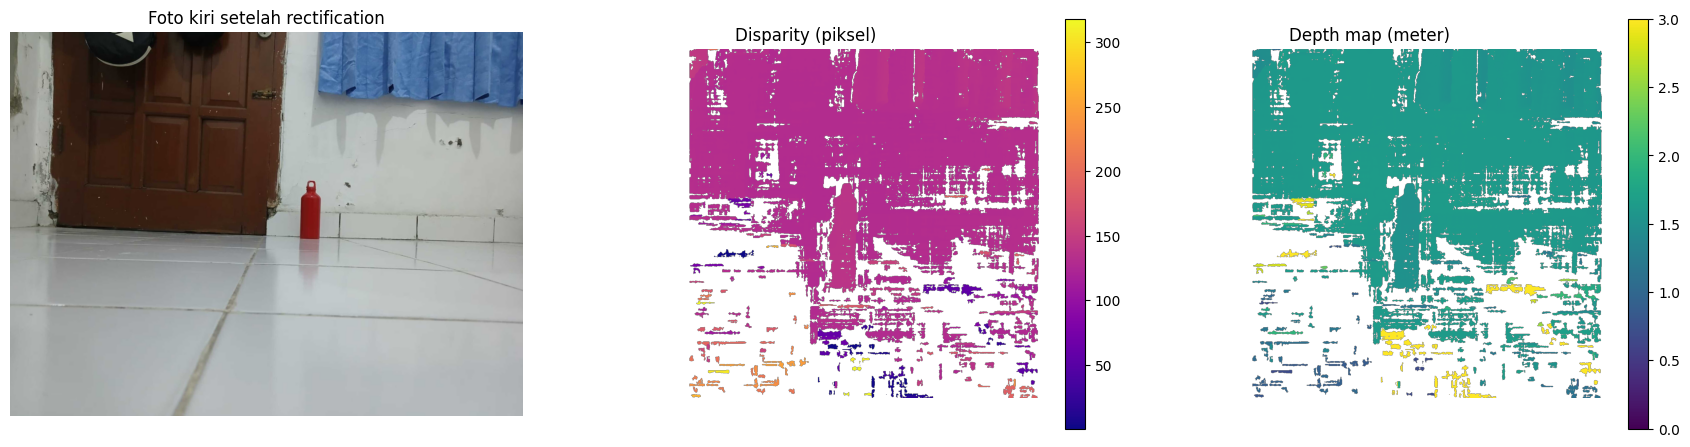


Cell 7 selesai.


In [ ]:
# Periksa hasil rectification, bukan alignment sebelum rectification
if STRICT_ALIGNMENT and median_dy_rect > 2.0:
    raise RuntimeError(
        f"Rectification belum cukup baik. "
        f"Median vertical error = {median_dy_rect:.2f} px.")

# Perkecil gambar agar proses StereoSGBM lebih ringan
TARGET_W = 1280
SCALE = min(1.0, TARGET_W / left_u.shape[1])

def shrink(img):
    if SCALE < 1.0:
        return cv2.resize(
            img,
            None,
            fx=SCALE,
            fy=SCALE,
            interpolation=cv2.INTER_AREA)
    return img

ls = shrink(lg)
rs = shrink(rg)
left_s = shrink(left_u)

# Sesuaikan focal length dengan ukuran gambar yang diperkecil
fx_rect = float(P1[0, 0])
fx_s = fx_rect * SCALE
baseline_m = BASELINE_CM / 100.0

# Tentukan rentang disparity
# Gunakan 320 agar rentangnya lebih lebar daripada pengaturan lama.
# Nilai numDisparities harus kelipatan 16.
SGBM_NUM_DISPARITIES = 320
SGBM_BLOCK_SIZE = 7

print("Ukuran gambar SGBM:", ls.shape[1], "x", ls.shape[0])
print("Skala gambar:", round(SCALE, 4))
print("Focal length setelah scaling:", round(fx_s, 2), "px")
print("Baseline:", baseline_m, "m")
print("Rentang disparity: 0 sampai", SGBM_NUM_DISPARITIES - 1, "px")

# Perkiraan disparity untuk beberapa jarak
for z_test in [0.5, 1.0, 1.5]:
    d_expected = fx_s * baseline_m / z_test
    print(
        f"Perkiraan disparity pada {z_test:.1f} m:",
        round(d_expected, 2), "px")

# Buat StereoSGBM
sgbm = cv2.StereoSGBM_create(
    minDisparity=0,
    numDisparities=SGBM_NUM_DISPARITIES,
    blockSize=SGBM_BLOCK_SIZE,

    P1=8 * SGBM_BLOCK_SIZE**2,
    P2=32 * SGBM_BLOCK_SIZE**2,

    disp12MaxDiff=1,
    uniquenessRatio=10,
    speckleWindowSize=100,
    speckleRange=2,

    preFilterCap=31,
    mode=cv2.STEREO_SGBM_MODE_SGBM_3WAY)

# Hitung disparity
raw = sgbm.compute(ls, rs).astype(np.float32)
disp = raw / 16.0

# Periksa rentang disparity
print("\nHASIL DISPARITY")
print("Disparity minimum:", float(np.min(disp)))
print("Disparity maksimum:", float(np.max(disp)))

# Piksel invalid dari OpenCV umumnya bernilai -1.
# Piksel yang mendekati batas atas juga dikeluarkan karena
# kemungkinan disparity sebenarnya berada di luar rentang pencarian.
valid = (
    np.isfinite(disp)
    & (disp > 0.5)
    & (disp < SGBM_NUM_DISPARITIES - 2))

saturated = (
    np.isfinite(disp)
    & (disp >= SGBM_NUM_DISPARITIES - 2))

print(
    "Piksel mendekati batas atas:",
    round(saturated.mean() * 100, 2), "%")

print(
    "Piksel disparity valid:",
    round(valid.mean() * 100, 2), "%")

if valid.sum() == 0:
    raise RuntimeError(
        "Tidak ada disparity valid. Periksa pasangan foto dan hasil rectification.")

print(
    "Disparity valid (persentil 5, 50, 95):",
    np.round(np.percentile(disp[valid], [5, 50, 95]), 2))

# Hitung depth menggunakan Z = f x B / d
Z = np.full(disp.shape, np.nan, dtype=np.float32)

Z[valid] = (
    fx_s * baseline_m
) / disp[valid]

print(
    "Depth valid (persentil 5, 50, 95):",
    np.round(np.nanpercentile(Z, [5, 50, 95]), 3),
    "meter")

# Visualisasi
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
ax[0].imshow(cv2.cvtColor(left_s, cv2.COLOR_BGR2RGB))
ax[0].set_title("Foto kiri setelah rectification")
im1 = ax[1].imshow(
    np.ma.masked_invalid(np.where(valid, disp, np.nan)),
    cmap="plasma")
ax[1].set_title("Disparity (piksel)")
fig.colorbar(im1, ax=ax[1], fraction=0.04)

im2 = ax[2].imshow(
    np.ma.masked_invalid(Z),
    cmap="viridis",
    vmin=0,
    vmax=3)
ax[2].set_title("Depth map (meter)")
fig.colorbar(im2, ax=ax[2], fraction=0.04)

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

# Simpan hasil
np.save(
    OUT / "disparity_px.npy",
    np.where(valid, disp, np.nan))

np.save(OUT / "depth_m.npy", Z)

np.savez(
    OUT / "stereo_meta.npz",
    scale=SCALE,
    fx_scaled=fx_s,
    fx_rectified=fx_rect,
    baseline_cm=BASELINE_CM,
    num_disp=SGBM_NUM_DISPARITIES,
    median_vertical_error_px=median_dy_rect)

cv2.imwrite(
    str(OUT / "left_rectified_sgbm.jpg"),
    left_s)

print("\nCell 7 selesai.")


INFORMASI ROI
Koordinat ROI gambar asli: (1400, 830)
Koordinat ROI gambar SGBM: (750, 445)
Jumlah seluruh piksel ROI: 289
Jumlah piksel valid: 289
Persentase piksel valid: 100.0 %

HASIL ESTIMASI JARAK
Median disparity : 139.06 px
Jarak estimasi   : 1.5227 m
Jarak meteran    : 1.5 m
Error            : 1.51 %


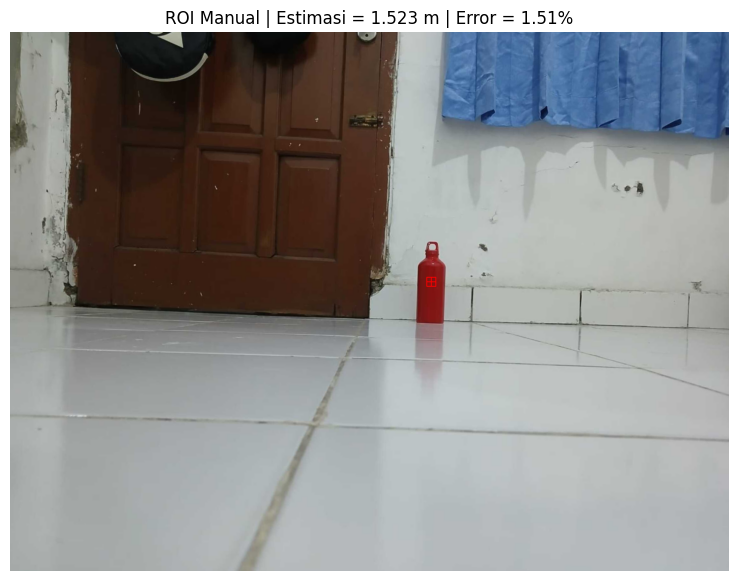

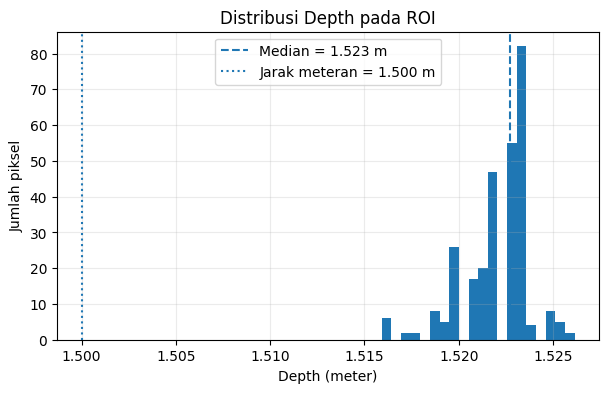

In [ ]:
# Koordinat ROI pada gambar asli
ROI_MODE = 'manual'
# ROI untuk objek botol pada percobaan 1,5 meter
ROI_X = 1400
ROI_Y = 830
ROI_RADIUS = 15

Z_TRUE_M = 1.5

# Ambil ukuran gambar
H_full, W_full = left_u.shape[:2]
h, w = Z.shape

# Pastikan titik ROI berada di dalam gambar
if not (0 <= ROI_X < W_full and 0 <= ROI_Y < H_full):
    raise ValueError(
        f"Koordinat ROI ({ROI_X}, {ROI_Y}) berada di luar gambar "
        f"{W_full} x {H_full}.")

if Z_TRUE_M <= 0:
    raise ValueError("Jarak sebenarnya harus lebih besar dari nol.")

# Ubah koordinat ROI ke ukuran gambar SGBM
rx = int(round(ROI_X * SCALE))
ry = int(round(ROI_Y * SCALE))
rr = max(3, int(round(ROI_RADIUS * SCALE)))

# Tentukan area ROI
x0 = max(0, rx - rr)
x1 = min(w, rx + rr + 1)

y0 = max(0, ry - rr)
y1 = min(h, ry + rr + 1)

roi_disp = disp[y0:y1, x0:x1]
roi_depth = Z[y0:y1, x0:x1]
roi_valid = valid[y0:y1, x0:x1]

# Ambil hanya piksel valid
valid_disp = roi_disp[roi_valid]
valid_depth = roi_depth[roi_valid]

total_pixels = roi_valid.size
valid_pixels = len(valid_depth)

valid_fraction = (
    valid_pixels / total_pixels * 100
    if total_pixels > 0 else 0)

print("INFORMASI ROI")
print("Koordinat ROI gambar asli:", (ROI_X, ROI_Y))
print("Koordinat ROI gambar SGBM:", (rx, ry))
print("Jumlah seluruh piksel ROI:", total_pixels)
print("Jumlah piksel valid:", valid_pixels)
print("Persentase piksel valid:", round(valid_fraction, 2), "%")

if valid_pixels < 10:
    raise RuntimeError(
        "Piksel depth valid dalam ROI kurang dari 10. "
        "Periksa posisi ROI atau kualitas disparity.")

# Hitung median disparity dan depth
D_MED = float(np.median(valid_disp))
Z_EST = float(np.median(valid_depth))

# Hitung error terhadap pengukuran meteran
ERROR_PCT = abs(Z_EST - Z_TRUE_M) / Z_TRUE_M * 100

# Tampilkan hasil pengukuran
print("\nHASIL ESTIMASI JARAK")
print("Median disparity :", round(D_MED, 2), "px")
print("Jarak estimasi   :", round(Z_EST, 4), "m")
print("Jarak meteran    :", round(Z_TRUE_M, 4), "m")
print("Error            :", round(ERROR_PCT, 2), "%")

# Visualisasi ROI
shown = cv2.cvtColor(left_u, cv2.COLOR_BGR2RGB).copy()

thickness = max(2, W_full // 800)

# Kotak ROI
cv2.rectangle(
    shown,
    (int(x0 / SCALE), int(y0 / SCALE)),
    (int((x1 - 1) / SCALE), int((y1 - 1) / SCALE)),
    (255, 0, 0),
    thickness
)

# Titik tengah ROI
cv2.drawMarker(
    shown,
    (ROI_X, ROI_Y),
    (255, 0, 0),
    cv2.MARKER_CROSS,
    30,
    thickness
)

plt.figure(figsize=(10, 7))
plt.imshow(shown)
plt.title(
    f"ROI Manual | Estimasi = {Z_EST:.3f} m | "
    f"Error = {ERROR_PCT:.2f}%"
)
plt.grid(True, alpha=0.25)
plt.axis("off")
plt.show()

# 11. Tampilkan distribusi depth di dalam ROI
plt.figure(figsize=(7, 4))
plt.hist(valid_depth, bins=20)
plt.axvline(
    Z_EST,
    linestyle="--",
    label=f"Median = {Z_EST:.3f} m"
)
plt.axvline(
    Z_TRUE_M,
    linestyle=":",
    label=f"Jarak meteran = {Z_TRUE_M:.3f} m"
)
plt.xlabel("Depth (meter)")
plt.ylabel("Jumlah piksel")
plt.title("Distribusi Depth pada ROI")
plt.legend()
plt.grid(alpha=0.25)
plt.show()


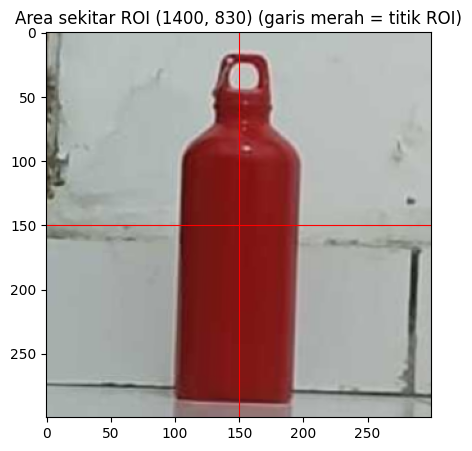

In [ ]:
half = 150
xa, xb = max(0, ROI_X - half), min(W_full, ROI_X + half)
ya, yb = max(0, ROI_Y - half), min(H_full, ROI_Y + half)
crop = left_u[ya:yb, xa:xb]
plt.figure(figsize=(5, 5))
plt.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
plt.axvline(ROI_X - xa, color='red', lw=0.8); plt.axhline(ROI_Y - ya, color='red', lw=0.8)
plt.title(f'Area sekitar ROI ({ROI_X}, {ROI_Y}) (garis merah = titik ROI)'); plt.show()

In [ ]:
TEST_ID = 'uji_03'  # GANTI: uji_01, uji_02, uji_03
csv_path = OUT / 'hasil_pengukuran.csv'
record = {
    'uji': TEST_ID, 'baseline_cm': BASELINE_CM, 'square_size_mm': SQUARE_SIZE_MM,
    'fx_px': round(float(P1[0, 0]), 3),
    'rms_px': round(float(rms), 3), 'median_vertical_error_px': round(median_dy_rect, 3),
    'disparity_roi_px': round(D_MED, 3), 'depth_est_m': round(Z_EST, 4),
    'depth_meter_m': round(Z_TRUE_M, 4), 'error_pct': round(ERROR_PCT, 2)}
rows = []
if csv_path.exists():
    with csv_path.open(encoding='utf-8', newline='') as fh: rows = list(csv.DictReader(fh))
rows = [r for r in rows if r['uji'] != TEST_ID] + [record]
with csv_path.open('w', encoding='utf-8', newline='') as fh:
    writer = csv.DictWriter(fh, fieldnames=list(record), extrasaction='ignore')
    writer.writeheader(); writer.writerows(rows)
print('Tersimpan:', csv_path)
for r in rows: print(r['uji'], '| jarak meteran', r['depth_meter_m'], 'm | estimasi', r['depth_est_m'], 'm | error', r['error_pct'], '%')

Tersimpan: repo_stereo/Praktikum_Stereo/output/hasil_pengukuran.csv
uji_03 | jarak meteran 1.5 m | estimasi 1.5227 m | error 1.51 %
